In [3]:
from IPython.core.display import HTML

HTML("""
<style>

h1 { color: blue !important; }
h2 { color: green !important; }
</style>
""")

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn import neighbors
from sklearn.metrics import mean_squared_error
from math import sqrt
from sklearn.metrics import r2_score
from google.colab import drive
# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory

import os
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
os.chdir("/content/drive/MyDrive/Inttrvu_ai_data_science_materials/Mentor_Session_12_KNN")

# Step 1: Read and explore the data

In [6]:
data = pd.read_csv("insurance.csv")

In [7]:
#age: age of primary beneficiary

#sex: insurance contractor gender, female, male

#bmi: Body mass index

#children: Number of children covered by health insurance / Number of dependents

#smoker: Smoking

#region: the beneficiary's residential area in the US, northeast, southeast, southwest, northwest.

#charges: Individual medical costs billed by health insurance

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
data.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [10]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
data['children'].value_counts()

,count
children,
0,574
1,324
2,240
3,157
4,25
5,18


# Step 2: Identify important features and relationships

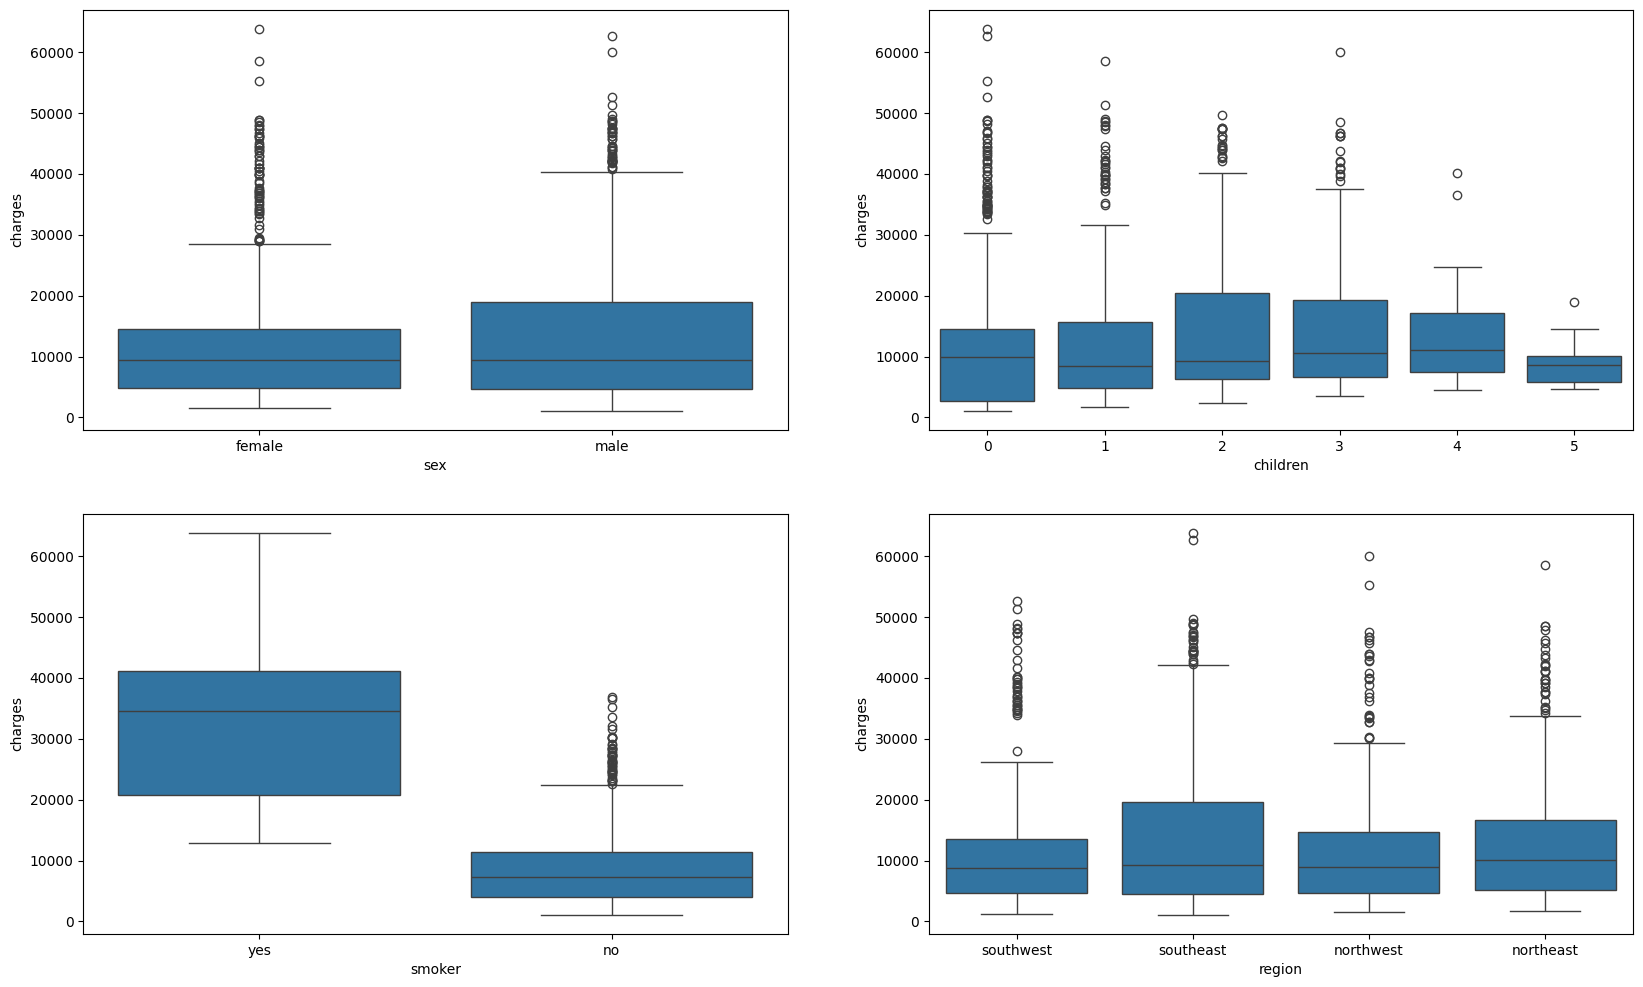

In [12]:
#Visualizing categorical variables

plt.figure(figsize=(20, 12))
plt.subplot(2,2,1)
sns.boxplot(x = 'sex', y = 'charges', data = data)
plt.subplot(2,2,2)
sns.boxplot(x = 'children', y = 'charges', data = data)
plt.subplot(2,2,3)
sns.boxplot(x = 'smoker', y = 'charges', data = data)
plt.subplot(2,2,4)
sns.boxplot(x = 'region', y = 'charges', data = data)
plt.show()

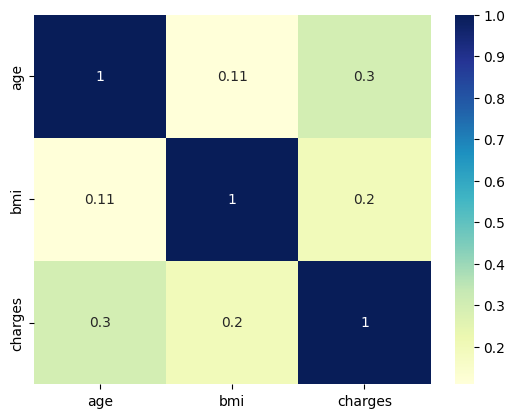

In [13]:
#Correlation of output with numerical variables

# plotting correlation heatmap
dataplot = sns.heatmap(data[['age', 'bmi', 'charges']].corr(), cmap="YlGnBu", annot=True)

# displaying heatmap
plt.show()

# Step 3: Create features

In [14]:
numerical_features = ['age','bmi','children']
categorical_features = ['sex', 'smoker', 'region']
data_features = data[numerical_features + categorical_features ]
data_features.head(10)

,age,bmi,children,sex,smoker,region
0,19,27.900,0,female,yes,southwest
1,18,33.770,1,male,no,southeast
2,28,33.000,3,male,no,southeast
3,33,22.705,0,male,no,northwest
4,32,28.880,0,male,no,northwest
5,31,25.740,0,female,no,southeast
6,46,33.440,1,female,no,southeast
7,37,27.740,3,female,no,northwest
8,37,29.830,2,male,no,northeast
9,60,25.840,0,female,no,northwest


In [15]:
# Convert data to numerical
data['smoker'] = data['smoker'].map({'yes': 1, "no": 0})
data['sex'] = data['sex'].map({'female': 1, "male": 0})

#Create dummy features for categorical variables

data = pd.get_dummies(data, columns= ['region'],drop_first=True)
data.head(10)

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False
5,31,1,25.740,0,0,3756.62160,False,True,False
6,46,1,33.440,1,0,8240.58960,False,True,False
7,37,1,27.740,3,0,7281.50560,True,False,False
8,37,0,29.830,2,0,6406.41070,False,False,False
9,60,1,25.840,0,0,28923.13692,True,False,False


# Step 4: Train test split and data scaling

In [16]:
def train_test_split_and_scale(data):
    y = data["charges"]
    x = data.drop('charges',axis=1)
    features = list(x.columns)
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state = 0)
    scaler = MinMaxScaler()
    x_train[numerical_features] = scaler.fit_transform(x_train[numerical_features])
    x_test[numerical_features] = scaler.transform(x_test[numerical_features])
    return x_train, x_test, y_train, y_test,features,scaler

In [17]:
x_train, x_test, y_train, y_test,features, scaler = train_test_split_and_scale(data)

#fit_and_evaluate_model(x_train, x_test, y_train, y_test)

In [18]:
x_train.head(10)

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
621,0.413043,0,0.488028,0.8,1,False,False,True
194,0.000000,0,0.496906,0.0,0,False,True,False
240,0.108696,1,0.557170,0.4,1,False,False,False
1168,0.304348,0,0.517622,0.4,0,False,False,True
1192,0.869565,1,0.442158,0.2,0,False,False,False
1279,0.152174,1,0.291364,0.4,0,True,False,False
49,0.391304,0,0.517622,0.2,1,False,True,False
597,0.347826,1,0.465160,0.2,0,False,False,False
539,0.760870,0,0.414044,0.0,0,False,True,False
425,0.586957,0,0.224644,1.0,0,False,True,False


In [19]:
x_train.describe()

,age,sex,bmi,children,smoker
count,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000
mean,0.458513,0.507477,0.397311,0.215888,0.204673
std,0.306266,0.500178,0.166438,0.242087,0.403651
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.173913,0.000000,0.278585,0.000000,0.000000
50%,0.456522,1.000000,0.388485,0.200000,0.000000
75%,0.717391,1.000000,0.506659,0.400000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000


# Step 5: Train and evaluate the model

In [20]:
rmse_val = [] #to store rmse values for different k
k_val = []
r_squared_score = []
for K in range(20):
    K = K+1
    model = neighbors.KNeighborsRegressor(n_neighbors = K)

    model.fit(x_train, y_train)  #just saving the data - no training as such
    y_test_pred=model.predict(x_test) #make prediction on test set
    error = sqrt(mean_squared_error(y_test,y_test_pred)) #calculate rmse
    rmse_val.append(error) #store rmse values
    r2_val = r2_score(y_test, y_test_pred)
    r_squared_score.append(r2_val)
    k_val.append(K)
    print('RMSE value for k= ' , K , 'is:', error)
    print("R-squared score: ", r2_val)

RMSE value for k=  1 is: 7124.260297137393
R-squared score:  0.6810463344506736
RMSE value for k=  2 is: 6205.570892243684
R-squared score:  0.758002141540709
RMSE value for k=  3 is: 5640.022078572151
R-squared score:  0.8001014480077053
RMSE value for k=  4 is: 5569.229408616295
R-squared score:  0.8050881446008861
RMSE value for k=  5 is: 5512.900240088975
R-squared score:  0.8090110208431355
RMSE value for k=  6 is: 5591.485904453701
R-squared score:  0.8035271663270083
RMSE value for k=  7 is: 5717.280966551418
R-squared score:  0.7945873852196204
RMSE value for k=  8 is: 5750.70858036822
R-squared score:  0.7921783635606222
RMSE value for k=  9 is: 5711.30503197606
R-squared score:  0.7950165720378627
RMSE value for k=  10 is: 5777.309535282032
R-squared score:  0.7902512827917646
RMSE value for k=  11 is: 5797.188416146159
R-squared score:  0.7888053698883682
RMSE value for k=  12 is: 5810.37449731526
R-squared score:  0.7878435254656159
RMSE value for k=  13 is: 5932.6641775519

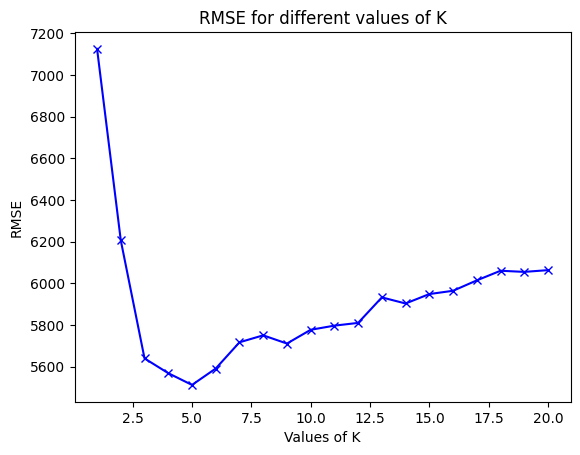

In [21]:
import matplotlib.pyplot as plt

plt.plot(k_val, rmse_val, 'bx-')
plt.xlabel('Values of K')
plt.ylabel('RMSE')
plt.title('RMSE for different values of K')
plt.show()

In [22]:
# Create result for best value of K =5

model = neighbors.KNeighborsRegressor(n_neighbors = 5)
model.fit(x_train, y_train)  #fit the model
y_test_pred=model.predict(x_test) #make prediction on test set
error = sqrt(mean_squared_error(y_test,y_test_pred)) #calculate rmse
r2_val = r2_score(y_test, y_test_pred)
print("RMSE value for K=5 is : " , error)
print("R-squared score for K=5 is: ", r2_val)

RMSE value for K=5 is :  5512.900240088975
R-squared score for K=5 is:  0.8090110208431355


In [23]:

data_pred = pd.DataFrame(y_test)
data_pred['predicted_charges'] = y_test_pred
data_pred['error']  = data_pred['predicted_charges'] - data_pred['charges']
data_pred['absolute error']  = abs(data_pred['error'] )
data_pred['error_percentge'] = (data_pred['absolute error']  / data_pred['charges'] ) * 100
data_pred.reset_index(drop=True, inplace =True)
data_pred.head(10)

,charges,predicted_charges,error,absolute error,error_percentge
0,9724.53000,9071.269400,-653.260600,653.260600,6.717657
1,8547.69130,8242.239640,-305.451660,305.451660,3.573499
2,45702.02235,38444.982734,-7257.039616,7257.039616,15.879034
3,12950.07120,11605.427900,-1344.643300,1344.643300,10.383289
4,9644.25250,11324.459740,1680.207240,1680.207240,17.421850
5,4500.33925,3733.951830,-766.387420,766.387420,17.029548
6,2198.18985,6080.566750,3882.376900,3882.376900,176.616997
7,11436.73815,16023.749478,4587.011328,4587.011328,40.107689
8,7537.16390,7114.130420,-423.033480,423.033480,5.612635
9,5425.02335,10768.761980,5343.738630,5343.738630,98.501671


In [34]:
data_pred.head(50)

,charges,predicted_charges,error,absolute error,error_percentge
0,9724.53000,9071.269400,-653.260600,653.260600,6.717657
1,8547.69130,8242.239640,-305.451660,305.451660,3.573499
2,45702.02235,38444.982734,-7257.039616,7257.039616,15.879034
3,12950.07120,11605.427900,-1344.643300,1344.643300,10.383289
4,9644.25250,11324.459740,1680.207240,1680.207240,17.421850
5,4500.33925,3733.951830,-766.387420,766.387420,17.029548
6,2198.18985,6080.566750,3882.376900,3882.376900,176.616997
7,11436.73815,16023.749478,4587.011328,4587.011328,40.107689
8,7537.16390,7114.130420,-423.033480,423.033480,5.612635
9,5425.02335,10768.761980,5343.738630,5343.738630,98.501671


In [24]:
x_test.head(10)

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
578,0.739130,0,0.383105,0.2,0,False,False,True
610,0.630435,1,0.360775,0.2,0,False,True,False
569,0.652174,0,0.661959,0.4,1,True,False,False
1034,0.934783,0,0.603175,0.0,0,True,False,False
198,0.717391,1,0.056228,0.0,0,True,False,False
981,0.347826,0,0.145682,0.0,0,False,False,False
31,0.000000,1,0.278585,0.0,0,False,False,False
1256,0.717391,1,0.549502,0.6,0,True,False,False
1219,0.434783,1,0.383374,0.6,0,True,False,False
1320,0.282609,0,0.406376,0.6,0,True,False,False


In [25]:
x_test[numerical_features] = scaler.inverse_transform(x_test[numerical_features])
x_test.reset_index(drop=True,inplace=True)
x_test.head(10)

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,52.0,0,30.200,1.0,0,False,False,True
1,47.0,1,29.370,1.0,0,False,True,False
2,48.0,0,40.565,2.0,1,True,False,False
3,61.0,0,38.380,0.0,0,True,False,False
4,51.0,1,18.050,0.0,0,True,False,False
5,34.0,0,21.375,0.0,0,False,False,False
6,18.0,1,26.315,0.0,0,False,False,False
7,51.0,1,36.385,3.0,0,True,False,False
8,38.0,1,30.210,3.0,0,True,False,False
9,31.0,0,31.065,3.0,0,True,False,False


In [29]:
data_pred_summary = pd.concat([x_test,data_pred],axis=1)
data_pred_summary.head(100)

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,charges,predicted_charges,error,absolute error,error_percentge
0,52.0,0,30.200,1.0,0,False,False,True,9724.53000,9071.269400,-653.260600,653.260600,6.717657
1,47.0,1,29.370,1.0,0,False,True,False,8547.69130,8242.239640,-305.451660,305.451660,3.573499
2,48.0,0,40.565,2.0,1,True,False,False,45702.02235,38444.982734,-7257.039616,7257.039616,15.879034
3,61.0,0,38.380,0.0,0,True,False,False,12950.07120,11605.427900,-1344.643300,1344.643300,10.383289
4,51.0,1,18.050,0.0,0,True,False,False,9644.25250,11324.459740,1680.207240,1680.207240,17.421850
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,32.0,1,31.540,1.0,0,False,False,False,5148.55260,10598.131940,5449.579340,5449.579340,105.846823
96,55.0,0,30.685,0.0,1,False,False,False,42303.69215,33974.795044,-8328.897106,8328.897106,19.688346
97,44.0,0,30.200,2.0,1,False,False,True,38998.54600,33998.447600,-5000.098400,5000.098400,12.821243
98,31.0,1,32.775,2.0,0,True,False,False,5327.40025,5797.799400,470.399150,470.399150,8.829807


In [30]:
data_pred_summary.error_percentge.describe()

,error_percentge
count,268.000000
mean,37.067497
std,55.784556
min,0.085527
25%,5.932023
50%,14.896008
75%,44.525780
max,364.071345


In [32]:
data_pred_summary['absolute error'].describe()

,absolute error
count,268.000000
mean,3530.233509
std,4242.248483
min,6.714400
25%,433.314570
50%,1712.137409
75%,5149.083867
max,20549.261390


In [27]:
print("Average value of insurance charges: ", round(data_pred_summary['charges'].mean()))
print("Average absolute error in predicted insurance charges: ", round(data_pred_summary['absolute error'].mean()))

Average value of insurance charges:  13547
Average absolute error in predicted insurance charges:  3530


In [28]:
data_pred_summary.to_csv("data_pred_summary.csv",index= False)